In [12]:
import pennylane as qml

In [13]:
solution = "101"

In [14]:
def phase_oracle(target, wires):
    wires = list(wires)

    if len(target) != len(wires) or not target or any(
        bit not in "01" for bit in target
    ):
        raise ValueError("Provide one binary target bit per wire.")

    # Map the target state to the all-ones state.
    for bit, wire in zip(target, wires):
        if bit == "0":
            qml.PauliX(wires=wire)

    # Flip the phase of the all-ones state.
    if len(wires) == 1:
        qml.PauliZ(wires=wires[0])
    else:
        qml.ctrl(qml.PauliZ, control=wires[:-1])(wires=wires[-1])

    # Undo the mapping.
    for bit, wire in zip(target, wires):
        if bit == "0":
            qml.PauliX(wires=wire)

In [18]:
grover = qml.device("default.qubit", wires=3)

@qml.qnode(grover)
def circuit(target, iterations=2):
    for wire in grover.wires:
        qml.Hadamard(wires=wire)

    for _ in range(iterations):
        phase_oracle(target, grover.wires)
        qml.GroverOperator(wires=grover.wires)

    return qml.probs(wires=grover.wires)

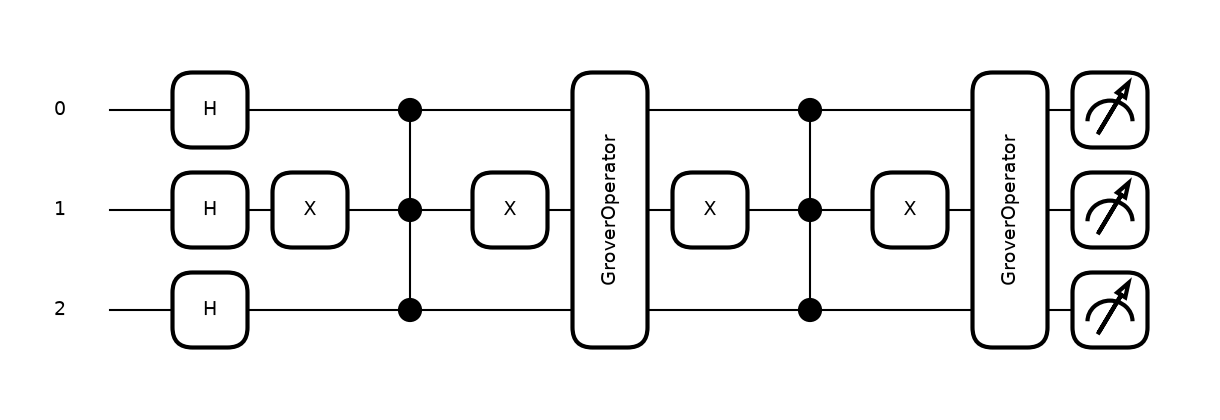

In [20]:
import matplotlib.pyplot as plt

fig, ax = qml.draw_mpl(circuit)(solution)
plt.show()

In [21]:
probabilities = circuit(solution)

for index, probability in enumerate(probabilities):
    state = format(index, f"0{len(grover.wires)}b")
    print(f"|{state}>: {probability:.4%}")

|000>: 0.7812%
|001>: 0.7812%
|010>: 0.7812%
|011>: 0.7812%
|100>: 0.7812%
|101>: 94.5312%
|110>: 0.7812%
|111>: 0.7812%
